# LLM Assignment 3 — Task 1

This notebook implements **Task 1** from the supplied assignment specification.

- 3-class Gaussian dataset: FCNN with **one hidden layer**
- 3-class spiral dataset: FCNN with **two hidden layers**
- FCNN and backpropagation implemented **from scratch using NumPy**
- Sigmoid activation and instantaneous squared-error loss
- Stochastic gradient descent (one sample at a time)
- 60/20/20 split **within every class**
- Architecture selection using **validation accuracy**, with validation squared error as the deterministic tie-breaker
- Validation confusion matrices for **every tested architecture**
- Error curves for the selected architecture
- Decision-region plots for the selected architecture
- 3-D activation surfaces for **every hidden/output node** on train, validation and test sets
- Single-neuron one-vs-rest baseline

In [1]:
import os, random, copy, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Setup complete")


Setup complete


## Part I — Task 1: Synthetic data


In [2]:
def one_hot(y, n_classes):
    Y = np.zeros((len(y), n_classes), dtype=float)
    Y[np.arange(len(y)), y] = 1.0
    return Y

def split_per_class(X, y, train_ratio=.60, val_ratio=.20, seed=SEED):
    rng = np.random.default_rng(seed)
    parts = [[], [], []]
    labels = [[], [], []]

    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(round(train_ratio*n))
        n_val = int(round(val_ratio*n))
        inds = [idx[:n_train], idx[n_train:n_train+n_val], idx[n_train+n_val:]]
        for k in range(3):
            parts[k].append(X[inds[k]])
            labels[k].append(y[inds[k]])

    out = []
    for k in range(3):
        Xk = np.vstack(parts[k])
        yk = np.concatenate(labels[k])
        p = rng.permutation(len(yk))
        out.append((Xk[p], yk[p]))
    return out[0], out[1], out[2]


In [3]:
# Dataset 1: three compact, linearly separable Gaussian clusters.
def make_gaussian_dataset(n_per_class=500, seed=SEED):
    rng = np.random.default_rng(seed)
    means = np.array([[-2.5,-1.5], [2.5,-1.0], [0.0,2.8]])
    covs = [
        np.array([[.45,0],[0,.45]]),
        np.array([[.50,.05],[.05,.40]]),
        np.array([[.40,-.04],[-.04,.50]])
    ]
    X, y = [], []
    for c in range(3):
        X.append(rng.multivariate_normal(means[c], covs[c], n_per_class))
        y.append(np.full(n_per_class,c))
    return np.vstack(X), np.concatenate(y)

Xg, yg = make_gaussian_dataset()
train_g, val_g, test_g = split_per_class(Xg, yg)

print(Xg.shape, np.bincount(yg))


(1500, 2) [500 500 500]


In [4]:
# Dataset 2: interleaving 3-arm spiral.
def make_spiral_dataset(n_per_class=500, noise=.20, seed=SEED):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for c in range(3):
        r = np.linspace(.15,1.0,n_per_class)
        theta = 2.2*r + c*2*np.pi/3
        theta += rng.normal(0,noise,n_per_class)
        X.append(np.c_[r*np.cos(theta), r*np.sin(theta)])
        y.append(np.full(n_per_class,c))
    return np.vstack(X), np.concatenate(y)

Xs, ys = make_spiral_dataset()
train_s, val_s, test_s = split_per_class(Xs, ys)

print(Xs.shape, np.bincount(ys))


(1500, 2) [500 500 500]


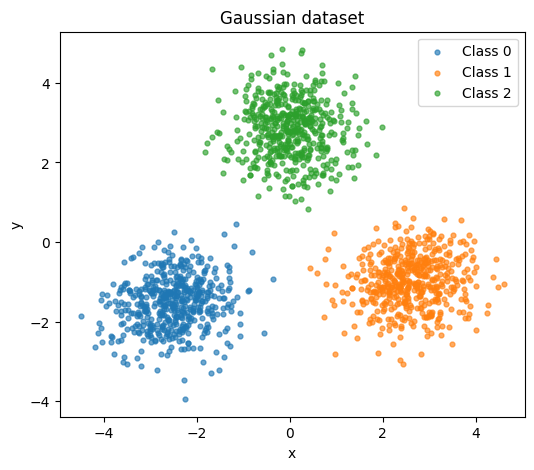

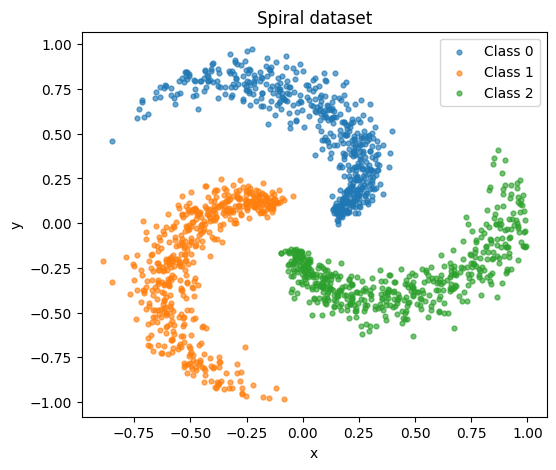

In [5]:
def plot_dataset(X,y,title):
    plt.figure(figsize=(6,5))
    for c in np.unique(y):
        plt.scatter(X[y==c,0], X[y==c,1], s=12, alpha=.65, label=f"Class {c}")
    plt.xlabel("x"); plt.ylabel("y"); plt.title(title); plt.legend(); plt.show()

plot_dataset(Xg,yg,"Gaussian dataset")
plot_dataset(Xs,ys,"Spiral dataset")


## Task 1 — FCNN from scratch


In [6]:
class ScratchFCNN:
    def __init__(self, layer_sizes, seed=SEED):
        self.layer_sizes = list(layer_sizes)
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for fan_in, fan_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            limit = np.sqrt(6/(fan_in+fan_out))
            self.W.append(rng.uniform(-limit,limit,(fan_in,fan_out)))
            self.b.append(np.zeros((1,fan_out)))

    @staticmethod
    def sigmoid(z):
        z = np.clip(z,-50,50)
        return 1/(1+np.exp(-z))

    @staticmethod
    def sigmoid_derivative(a):
        return a*(1-a)

    def forward(self,X,cache=False):
        A=X
        activations=[A]
        zs=[]
        for W,b in zip(self.W,self.b):
            z=A@W+b
            zs.append(z)
            A=self.sigmoid(z)
            activations.append(A)
        return (A,activations,zs) if cache else A

    def predict(self,X):
        return np.argmax(self.forward(X),axis=1)

    def accuracy(self,X,y):
        return np.mean(self.predict(X)==y)

    def average_squared_error(self,X,Y):
        P=self.forward(X)
        return np.mean(.5*np.sum((Y-P)**2,axis=1))

    def train_sgd(self,X,Y,epochs=300,lr=.5,tol=1e-5,seed=SEED):
        rng=np.random.default_rng(seed)
        history=[]
        for epoch in range(epochs):
            for i in rng.permutation(len(X)):
                xi=X[i:i+1]; yi=Y[i:i+1]
                pred,A,Z=self.forward(xi,cache=True)
                delta=(pred-yi)*self.sigmoid_derivative(A[-1])
                dW=[None]*len(self.W); db=[None]*len(self.b)
                for l in range(len(self.W)-1,-1,-1):
                    dW[l]=A[l].T@delta
                    db[l]=delta
                    if l>0:
                        delta=(delta@self.W[l].T)*self.sigmoid_derivative(A[l])
                for l in range(len(self.W)):
                    self.W[l]-=lr*dW[l]
                    self.b[l]-=lr*db[l]
            err=self.average_squared_error(X,Y)
            history.append(err)
            if epoch>0 and abs(history[-1]-history[-2])<tol:
                break
        return history


In [7]:
def run_task1(Xtr, ytr, Xv, yv, configs, epochs=300, lr=.5):
    Ytr = one_hot(ytr, 3)
    rows, models, histories = [], {}, {}

    for hidden in configs:
        arch = [2] + list(hidden) + [3]
        key = str(arch)
        model = ScratchFCNN(arch, seed=SEED)
        hist = model.train_sgd(Xtr, Ytr, epochs=epochs, lr=lr, seed=SEED)

        rows.append({
            "architecture": key,
            "hidden_nodes": str(hidden),
            "epochs": len(hist),
            "validation_accuracy": model.accuracy(Xv, yv),
            "validation_error": model.average_squared_error(Xv, one_hot(yv, 3))
        })
        models[key] = model
        histories[key] = hist

    # Select using validation accuracy only, as in the original experiment.
    # A stable sort preserves the explicit architecture order when validation
    # accuracies tie, making the selection deterministic and reproducible.
    results = (pd.DataFrame(rows)
               .sort_values("validation_accuracy", ascending=False, kind="mergesort")
               .reset_index(drop=True))
    return results, models, histories

gaussian_configs = [(2,), (3,), (5,), (8,), (12,), (16,)]
spiral_configs = [(4,4), (6,6), (8,8), (12,8), (16,12), (20,16)]

gauss_results, gauss_models, gauss_histories = run_task1(
    train_g[0], train_g[1], val_g[0], val_g[1], gaussian_configs)

spiral_results, spiral_models, spiral_histories = run_task1(
    train_s[0], train_s[1], val_s[0], val_s[1], spiral_configs)

print("Gaussian architecture search — ranked by validation accuracy")
display(gauss_results)
print("Spiral architecture search — ranked by validation accuracy")
display(spiral_results)

Gaussian architecture search — ranked by validation accuracy


,architecture,hidden_nodes,epochs,validation_accuracy,validation_error
0,"[2, 2, 3]","(2,)",31,1.0,0.000883
1,"[2, 3, 3]","(3,)",31,1.0,0.000502
2,"[2, 5, 3]","(5,)",23,1.0,0.000702
3,"[2, 8, 3]","(8,)",24,1.0,0.000269
4,"[2, 12, 3]","(12,)",21,1.0,0.000465
5,"[2, 16, 3]","(16,)",21,1.0,0.000399


Spiral architecture search — ranked by validation accuracy


,architecture,hidden_nodes,epochs,validation_accuracy,validation_error
0,"[2, 6, 6, 3]","(6, 6)",22,1.000000,0.002411
1,"[2, 16, 12, 3]","(16, 12)",33,1.000000,0.001343
2,"[2, 20, 16, 3]","(20, 16)",33,1.000000,0.001654
3,"[2, 4, 4, 3]","(4, 4)",66,0.996667,0.002389
4,"[2, 8, 8, 3]","(8, 8)",19,0.996667,0.003379
5,"[2, 12, 8, 3]","(12, 8)",36,0.996667,0.001872


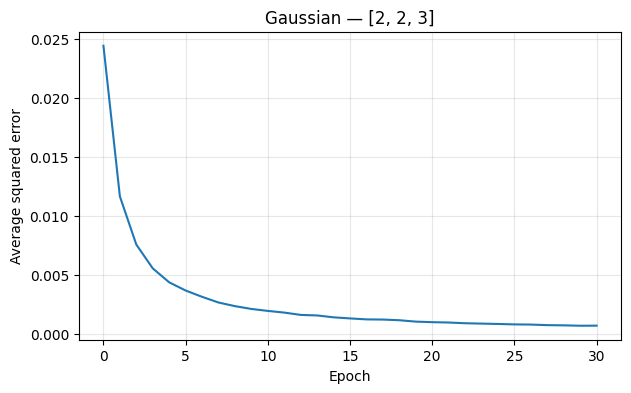

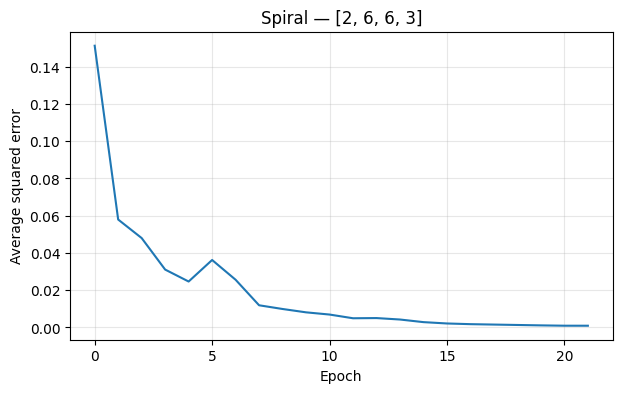

In [8]:
def plot_best_error(results,histories,title):
    key=results.iloc[0]["architecture"]
    plt.figure(figsize=(7,4))
    plt.plot(histories[key])
    plt.xlabel("Epoch"); plt.ylabel("Average squared error")
    plt.title(f"{title} — {key}"); plt.grid(alpha=.3); plt.show()

best_g=gauss_models[gauss_results.iloc[0]["architecture"]]
best_s=spiral_models[spiral_results.iloc[0]["architecture"]]

plot_best_error(gauss_results,gauss_histories,"Gaussian")
plot_best_error(spiral_results,spiral_histories,"Spiral")



Gaussian — validation confusion matrices for every architecture
[2, 2, 3]: 100.00%
[2, 3, 3]: 100.00%
[2, 5, 3]: 100.00%
[2, 8, 3]: 100.00%
[2, 12, 3]: 100.00%
[2, 16, 3]: 100.00%


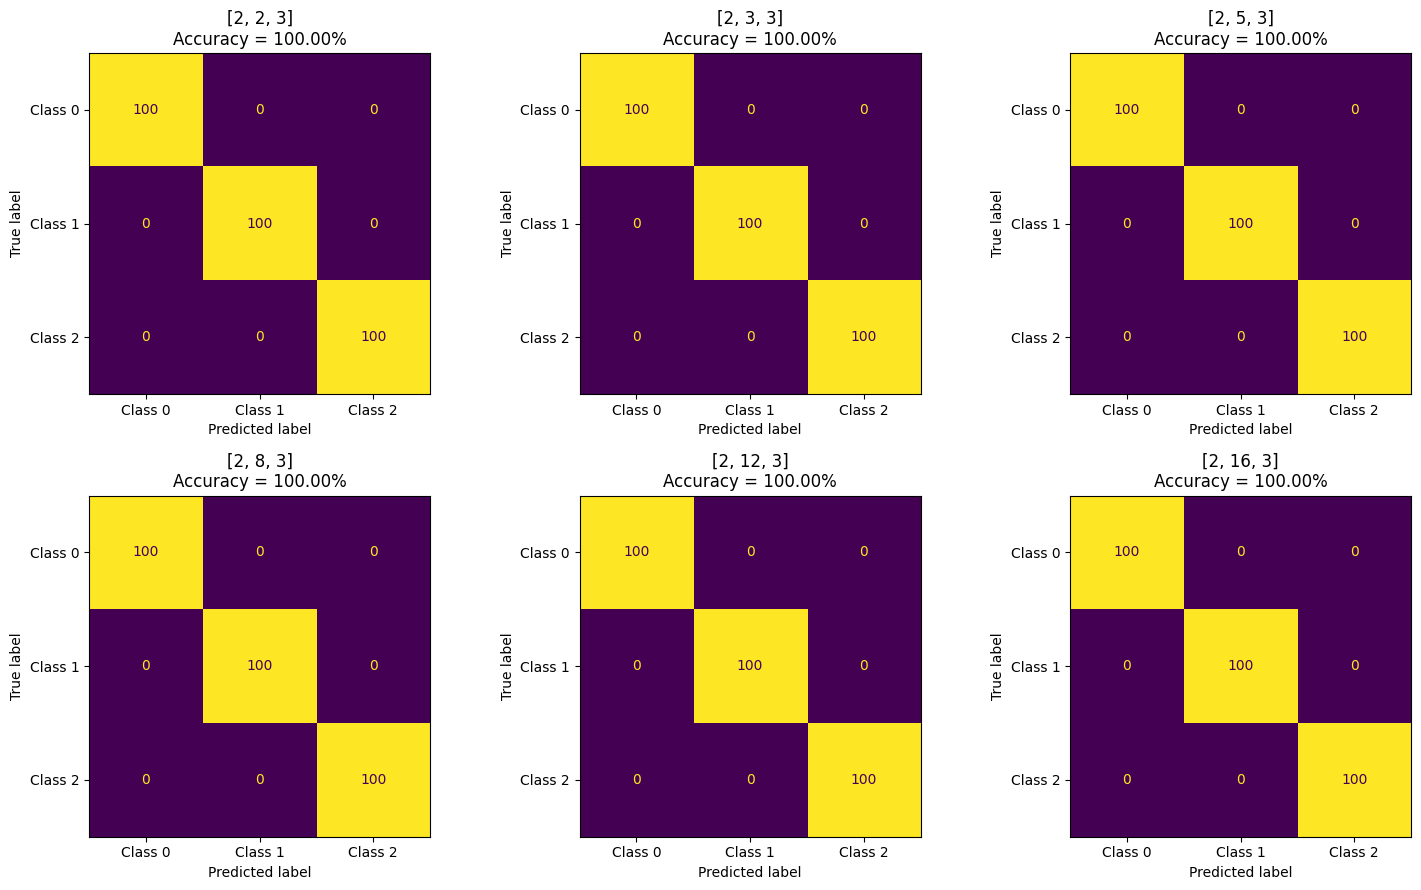


Spiral — validation confusion matrices for every architecture
[2, 6, 6, 3]: 100.00%
[2, 16, 12, 3]: 100.00%
[2, 20, 16, 3]: 100.00%
[2, 4, 4, 3]: 99.67%
[2, 8, 8, 3]: 99.67%
[2, 12, 8, 3]: 99.67%


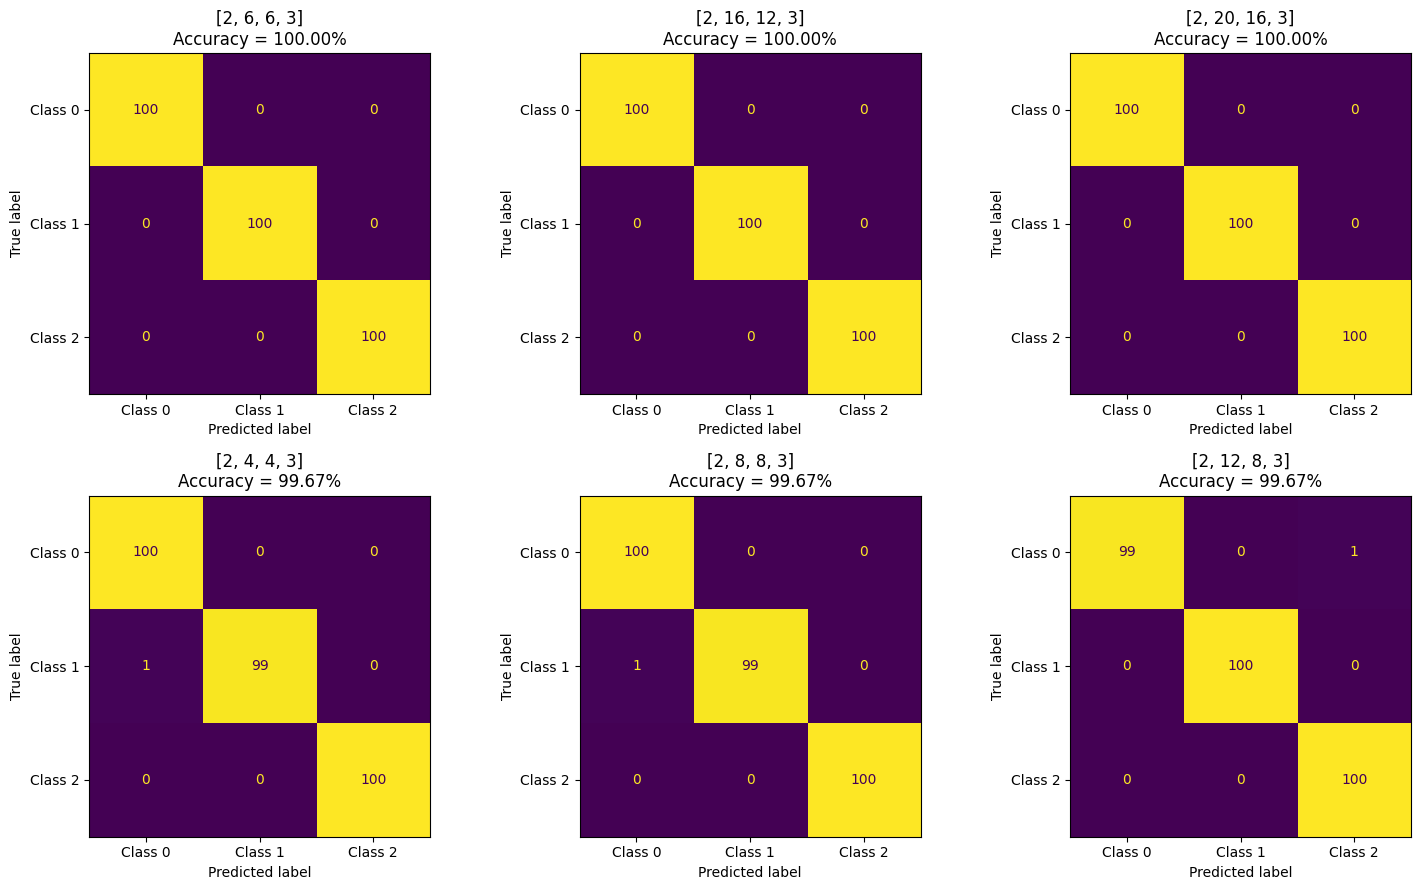


Selected Gaussian architecture: [2, 2, 3]
Selected Spiral architecture: [2, 6, 6, 3]
Gaussian — selected architecture — validation: accuracy = 100.00%
Gaussian — selected architecture — test: accuracy = 100.00%
Spiral — selected architecture — validation: accuracy = 100.00%
Spiral — selected architecture — test: accuracy = 100.00%


(array([[100,   0,   0],
        [  0, 100,   0],
        [  0,   0, 100]]),
 1.0)

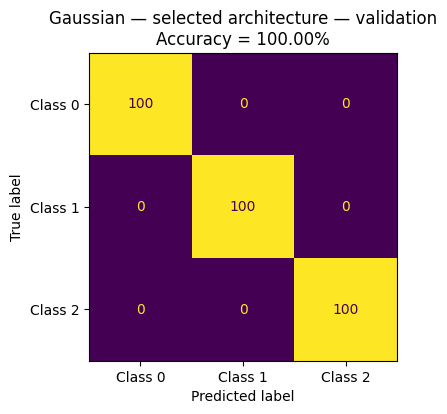

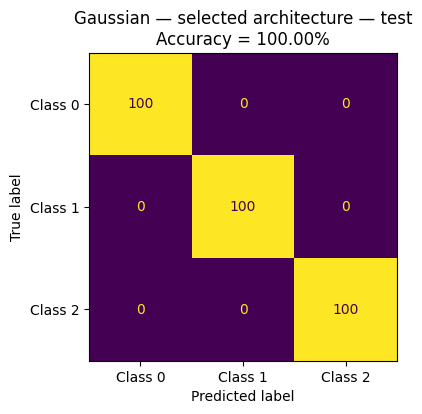

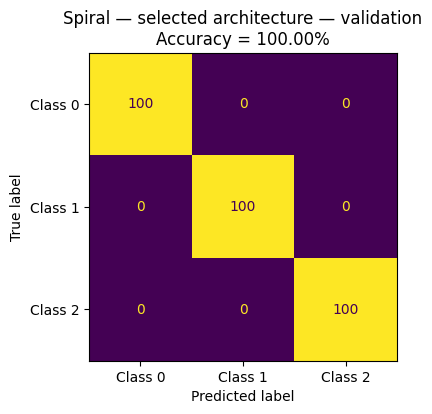

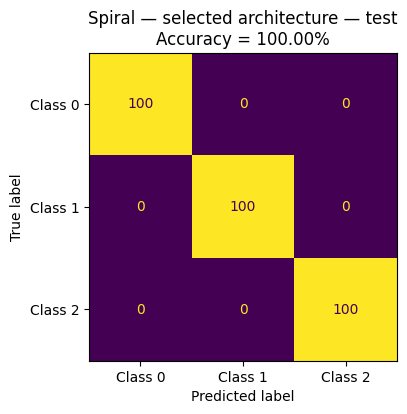

In [9]:
def show_cm(model, X, y, title, ax=None, print_result=True):
    pred = model.predict(X)
    cm = confusion_matrix(y, pred, labels=[0,1,2])
    acc = accuracy_score(y, pred)

    if print_result:
        print(f"{title}: accuracy = {acc*100:.2f}%")

    if ax is None:
        fig, ax = plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(cm, display_labels=["Class 0", "Class 1", "Class 2"]).plot(
        ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{title}\nAccuracy = {acc*100:.2f}%")
    return cm, acc

def plot_all_validation_confusion_matrices(results, models, Xv, yv, title):
    n = len(results)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.ravel()
    print(f"\n{title} — validation confusion matrices for every architecture")

    for i, row in results.iterrows():
        key = row["architecture"]
        _, acc = show_cm(models[key], Xv, yv, key, ax=axes[i], print_result=False)
        print(f"{key}: {acc*100:.2f}%")

    plt.tight_layout()
    plt.show()

# Requirement: validation confusion matrix + accuracy for EVERY tested architecture.
plot_all_validation_confusion_matrices(
    gauss_results, gauss_models, val_g[0], val_g[1], "Gaussian")
plot_all_validation_confusion_matrices(
    spiral_results, spiral_models, val_s[0], val_s[1], "Spiral")

# Best architecture is selected only from validation data.
best_g_key = gauss_results.iloc[0]["architecture"]
best_s_key = spiral_results.iloc[0]["architecture"]
best_g = gauss_models[best_g_key]
best_s = spiral_models[best_s_key]

print("\nSelected Gaussian architecture:", best_g_key)
print("Selected Spiral architecture:", best_s_key)

# For the selected architecture, report validation and test confusion matrices as required.
show_cm(best_g, val_g[0], val_g[1], "Gaussian — selected architecture — validation")
show_cm(best_g, test_g[0], test_g[1], "Gaussian — selected architecture — test")
show_cm(best_s, val_s[0], val_s[1], "Spiral — selected architecture — validation")
show_cm(best_s, test_s[0], test_s[1], "Spiral — selected architecture — test")

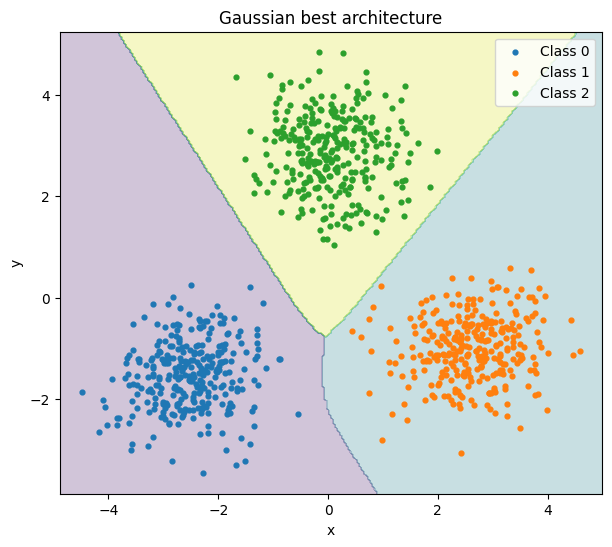

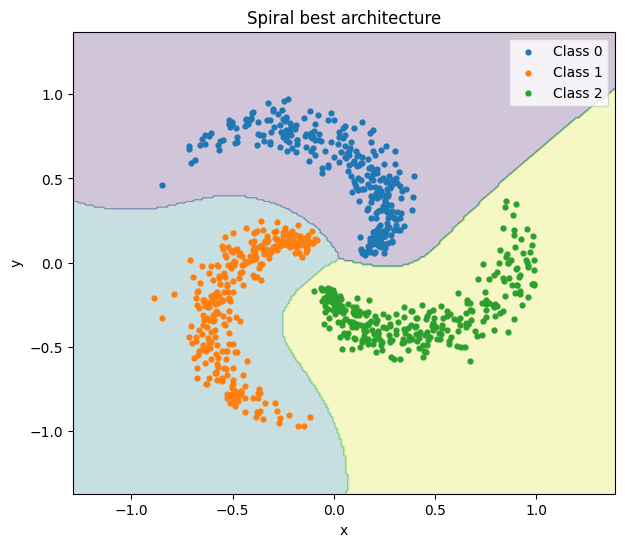

In [10]:
def plot_decision_regions(model,X,y,title,resolution=250):
    x0=np.linspace(X[:,0].min()-.4,X[:,0].max()+.4,resolution)
    x1=np.linspace(X[:,1].min()-.4,X[:,1].max()+.4,resolution)
    xx,yy=np.meshgrid(x0,x1)
    grid=np.c_[xx.ravel(),yy.ravel()]
    zz=model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(7,6))
    plt.contourf(xx,yy,zz,alpha=.25)
    for c in np.unique(y):
        plt.scatter(X[y==c,0],X[y==c,1],s=12,label=f"Class {c}")
    plt.xlabel("x"); plt.ylabel("y"); plt.title(title); plt.legend(); plt.show()

plot_decision_regions(best_g,train_g[0],train_g[1],"Gaussian best architecture")
plot_decision_regions(best_s,train_s[0],train_s[1],"Spiral best architecture")


Generating required activation surfaces for the selected Gaussian architecture...


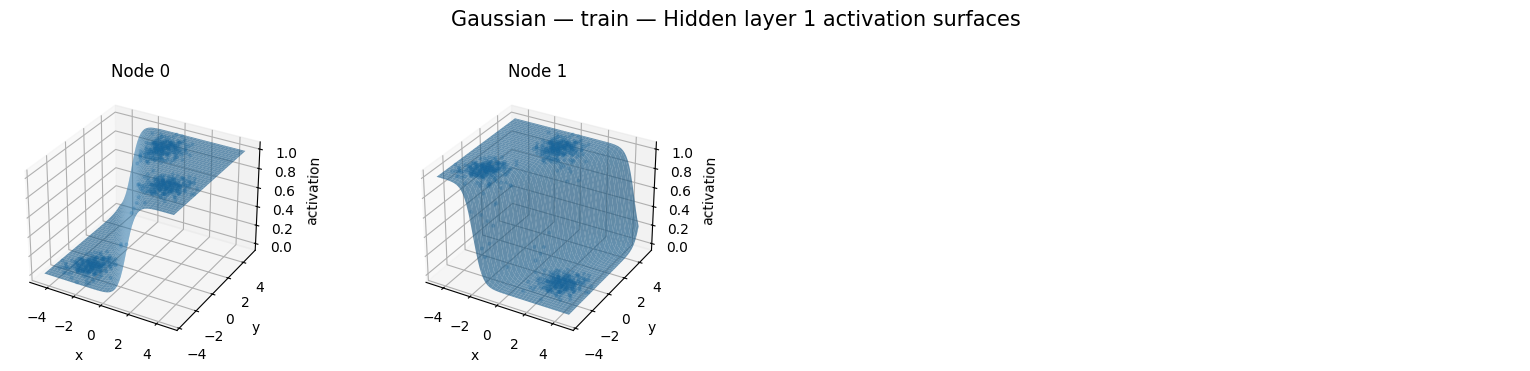

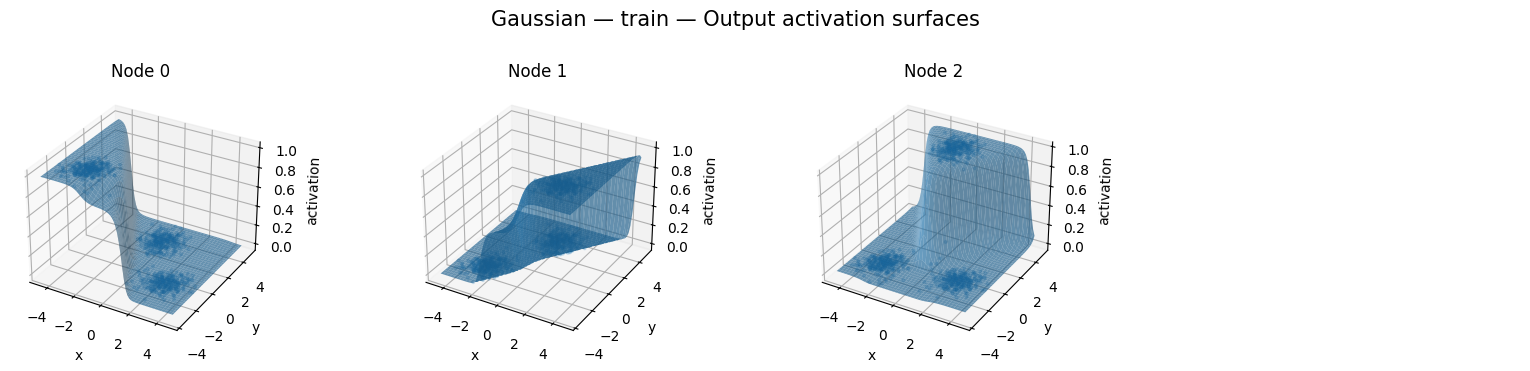

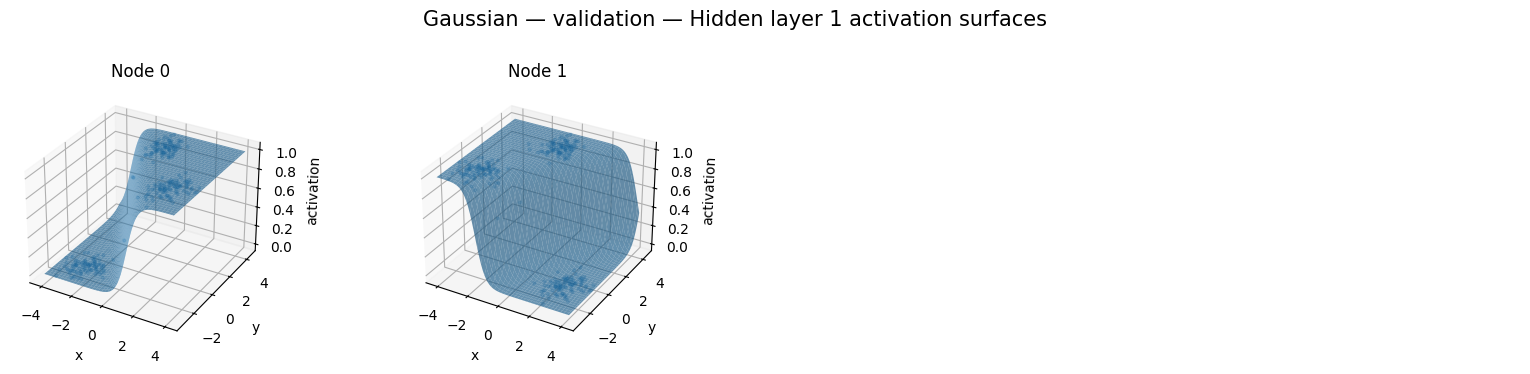

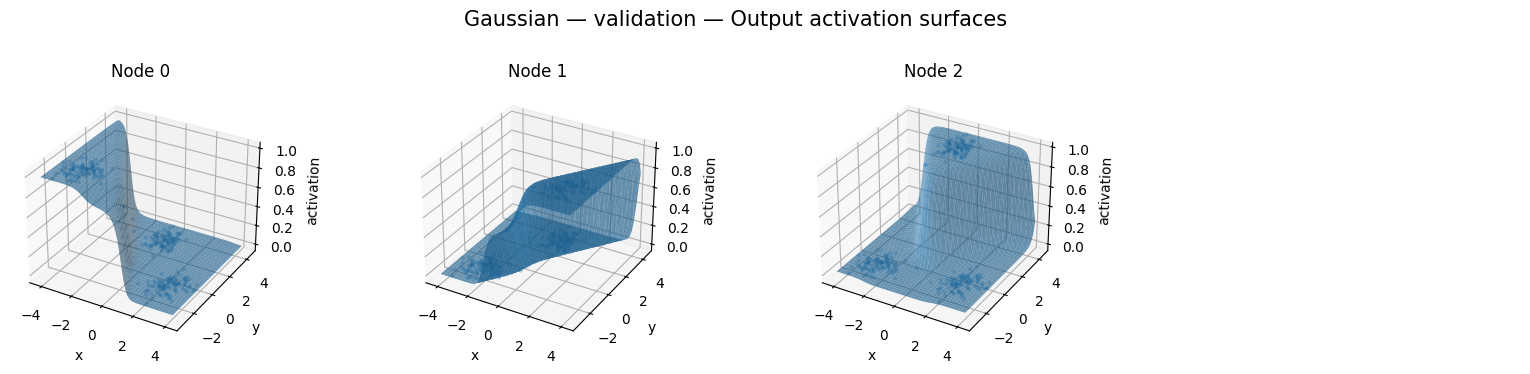

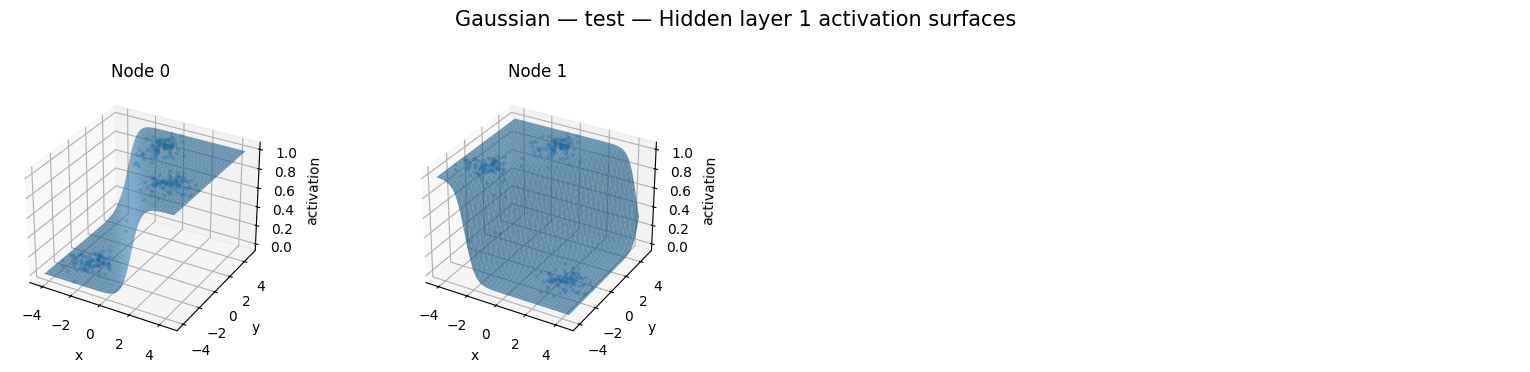

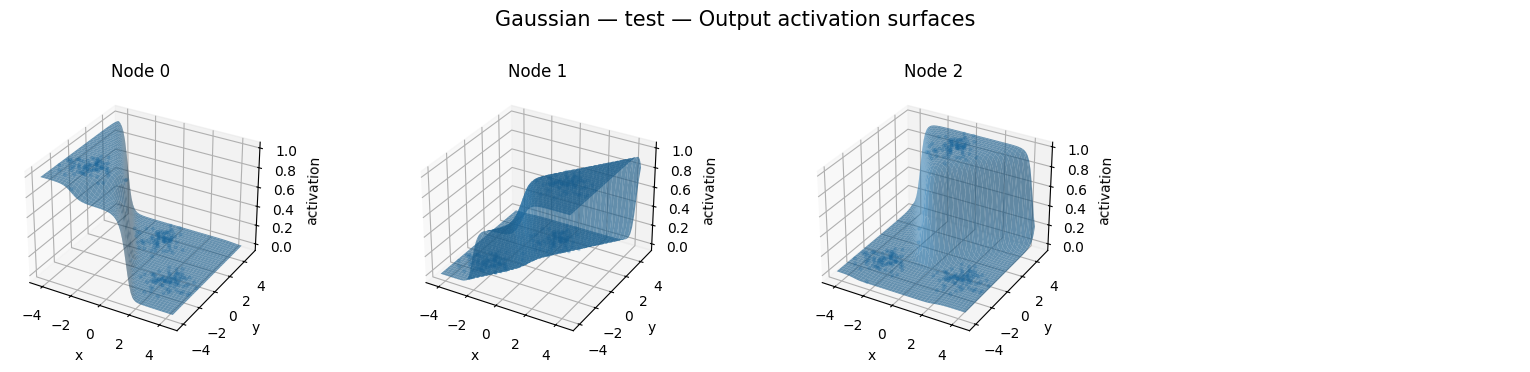

Generating required activation surfaces for the selected Spiral architecture...


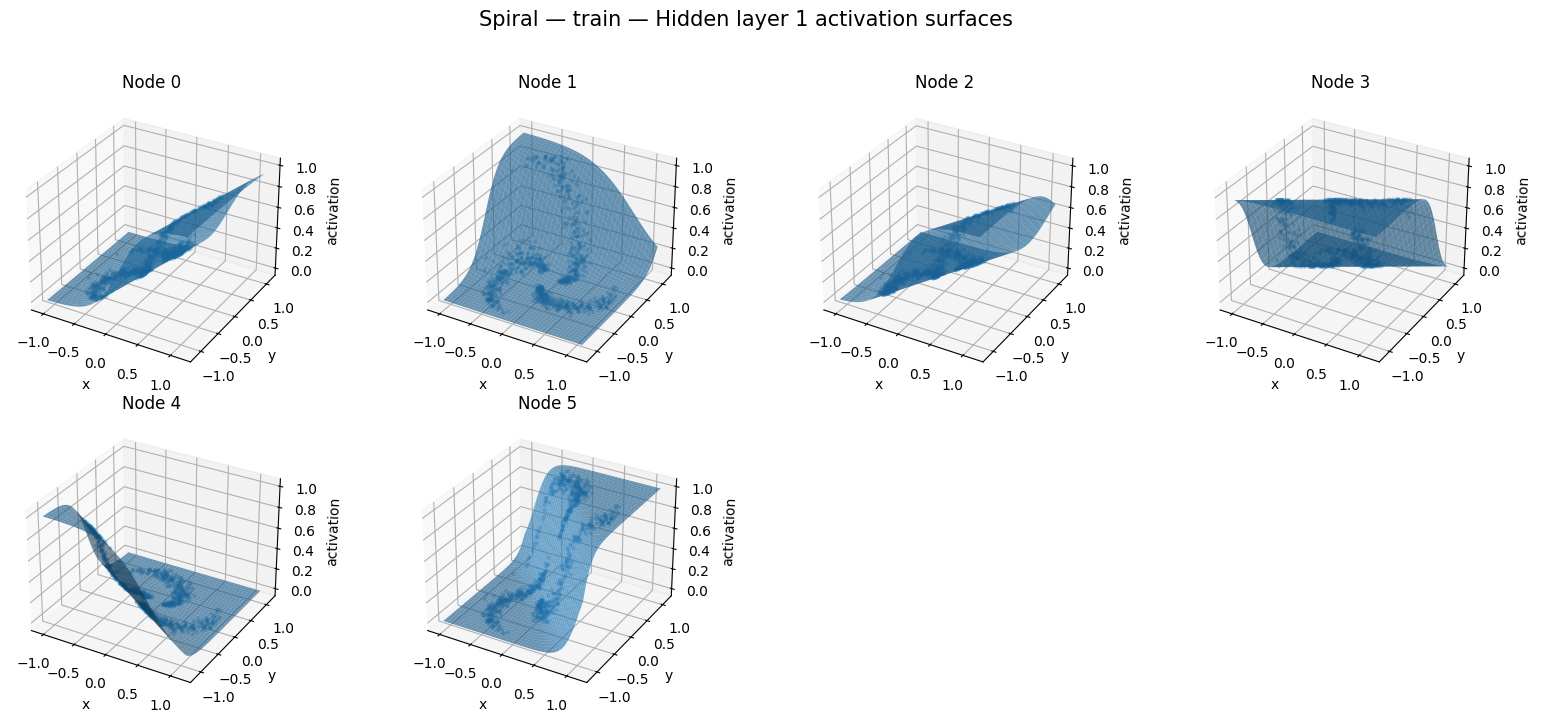

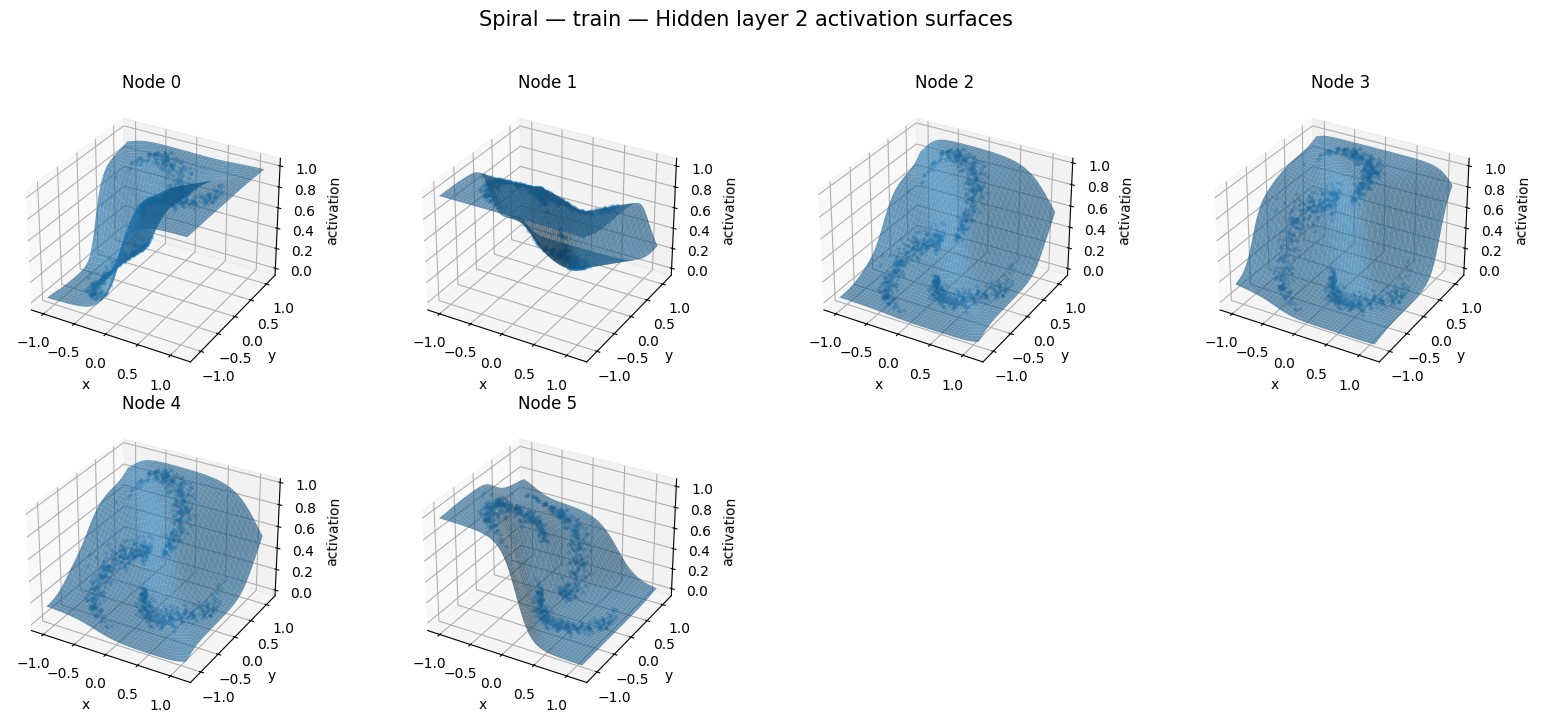

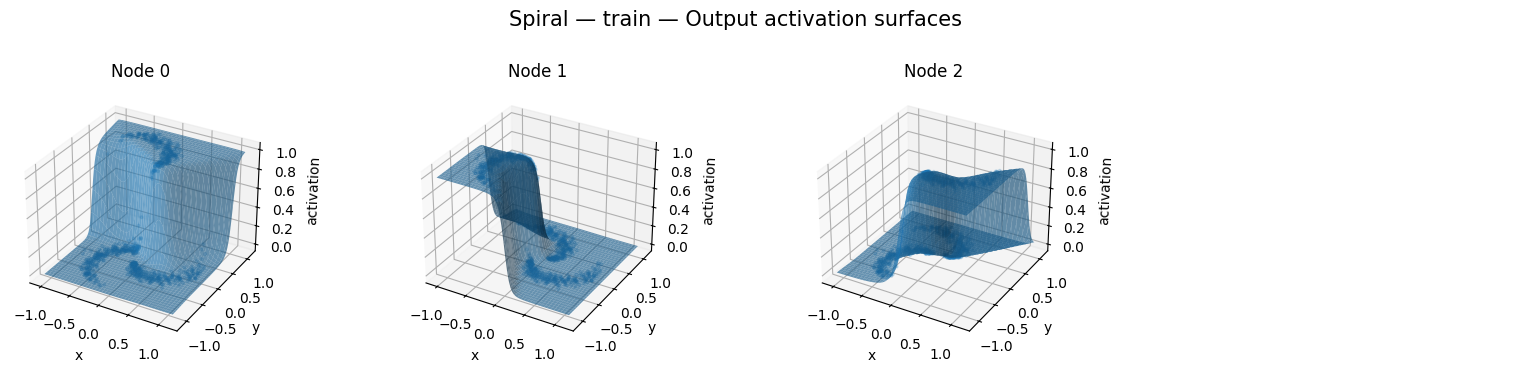

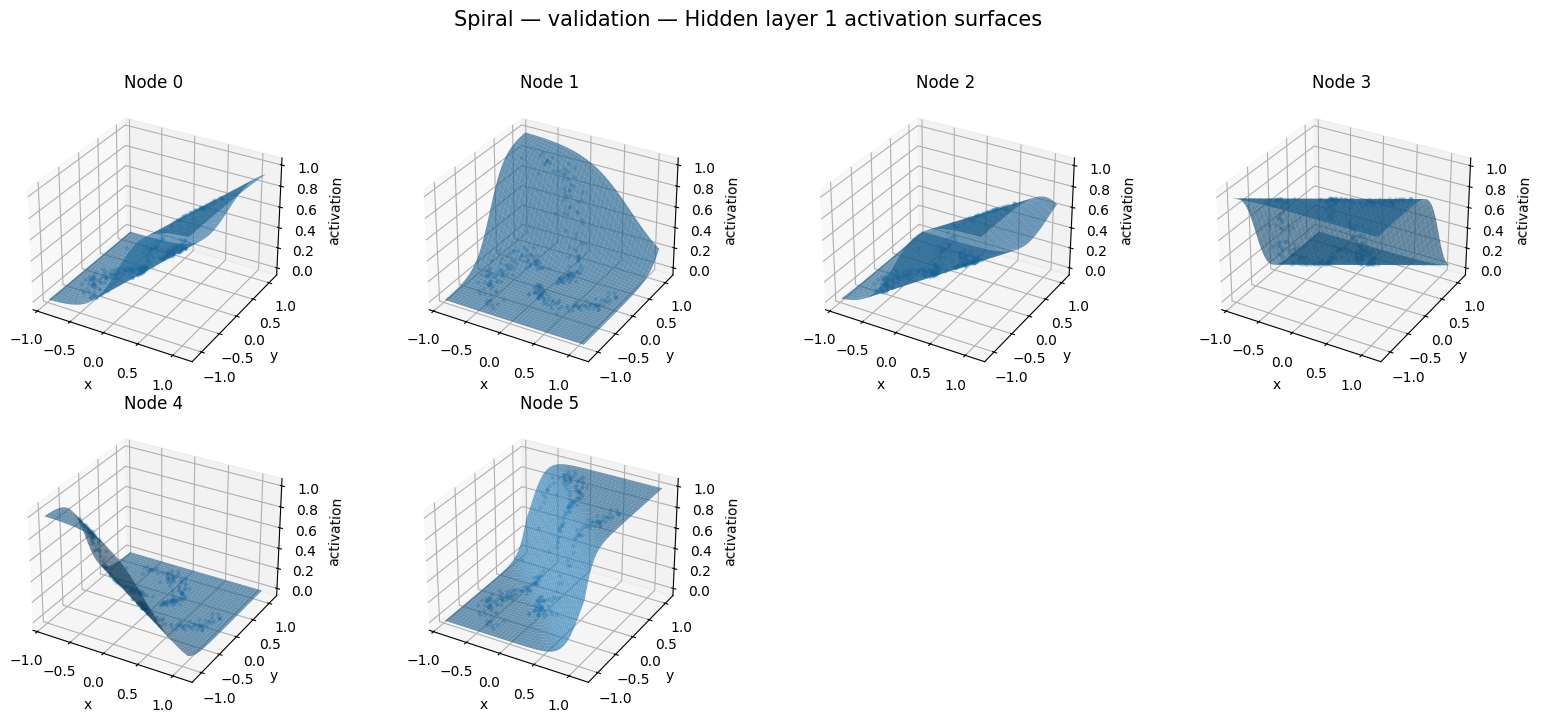

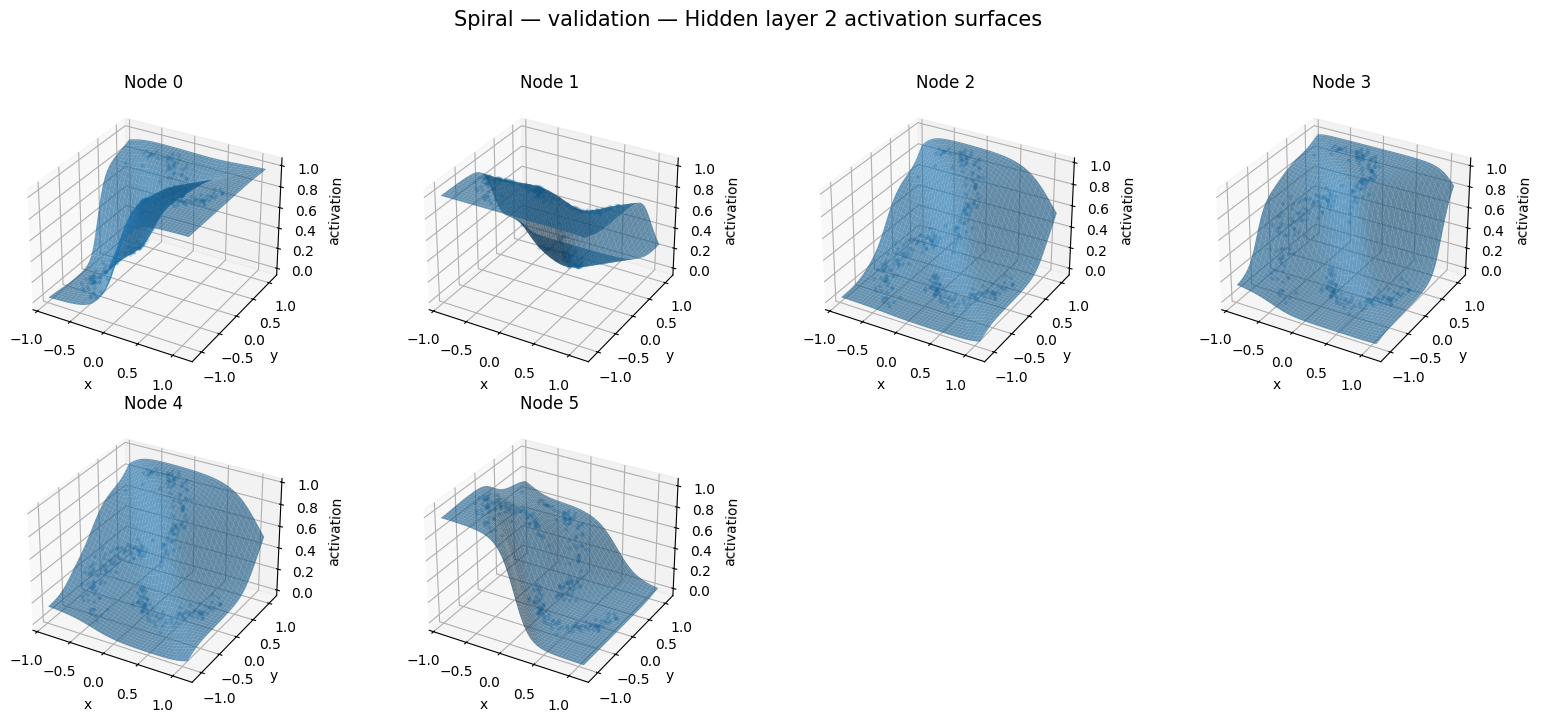

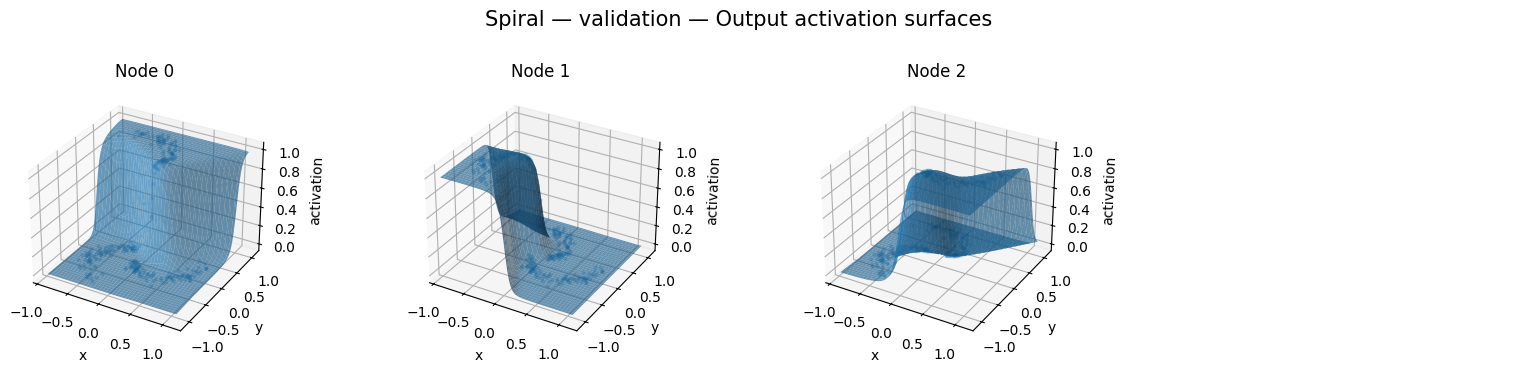

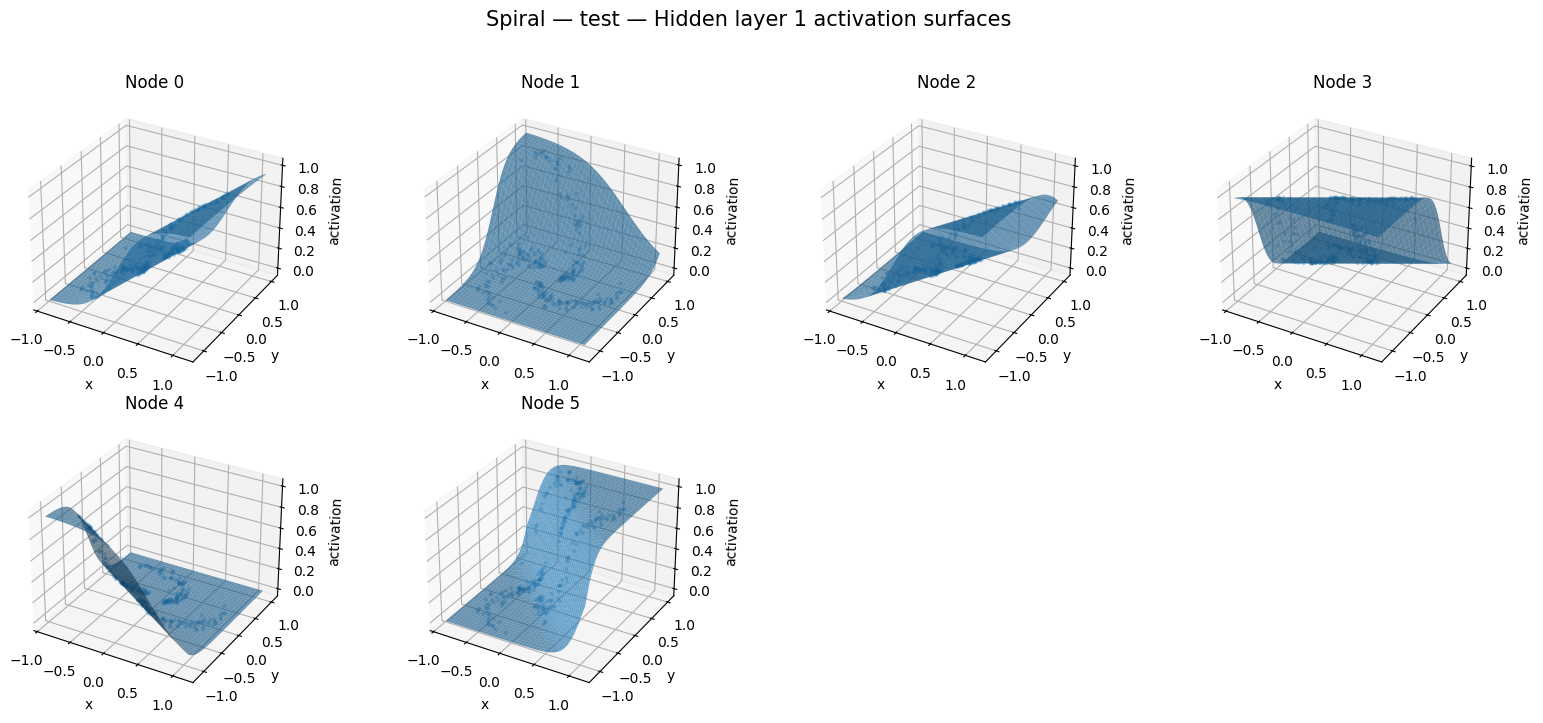

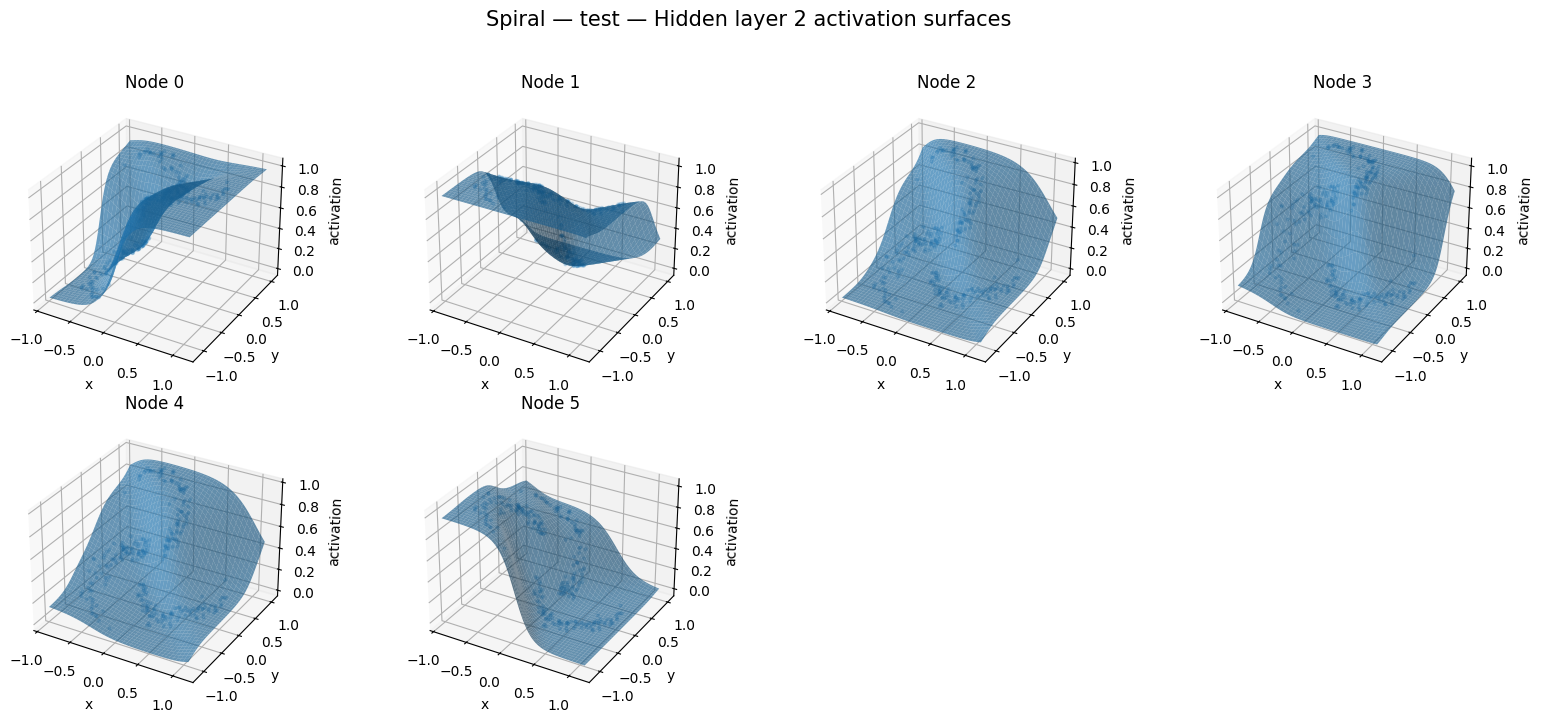

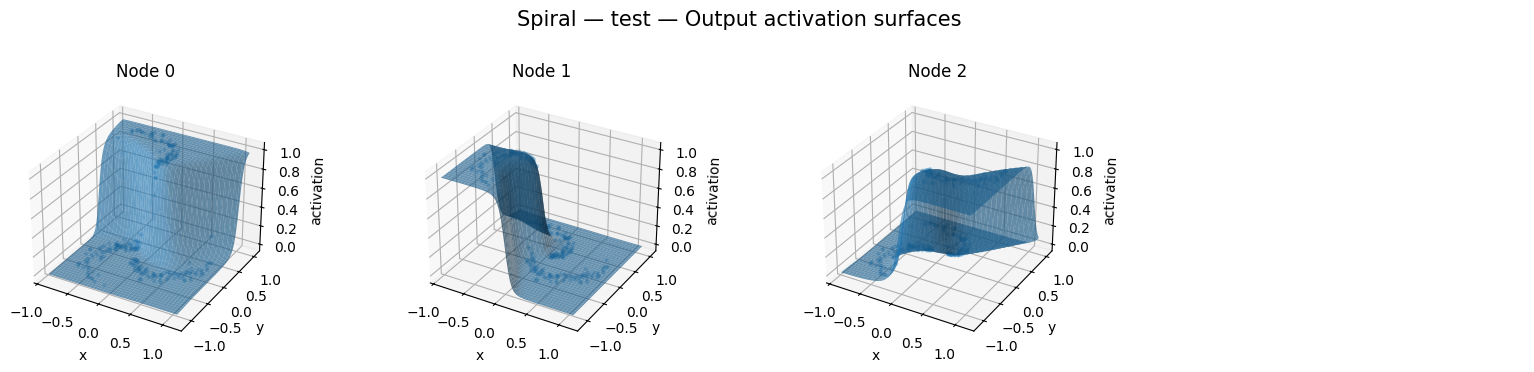

In [11]:
# 3-D activation surfaces for EVERY hidden/output node, for train/validation/test.
# To keep the notebook readable, all nodes belonging to one layer are shown as subplots
# in a single figure. This still provides a separate surface for every node.

def plot_node_surfaces(model, X, split_name, resolution=80):
    # Use the same plotting domain for a split so all node surfaces are comparable.
    pad = 0.15
    x0 = np.linspace(X[:,0].min()-pad, X[:,0].max()+pad, resolution)
    x1 = np.linspace(X[:,1].min()-pad, X[:,1].max()+pad, resolution)
    xx, yy = np.meshgrid(x0, x1)
    grid = np.c_[xx.ravel(), yy.ravel()]

    _, grid_acts, _ = model.forward(grid, cache=True)
    _, data_acts, _ = model.forward(X, cache=True)

    # activations[0] is the input. Plot every learned layer: hidden layers + output layer.
    for layer in range(1, len(grid_acts)):
        n_nodes = grid_acts[layer].shape[1]
        ncols = 4
        nrows = int(np.ceil(n_nodes / ncols))
        fig = plt.figure(figsize=(4*ncols, 3.6*nrows))

        layer_name = "Output" if layer == len(grid_acts)-1 else f"Hidden layer {layer}"
        fig.suptitle(f"{split_name} — {layer_name} activation surfaces", fontsize=15)

        for node in range(n_nodes):
            ax = fig.add_subplot(nrows, ncols, node+1, projection="3d")
            ax.plot_surface(
                xx, yy, grid_acts[layer][:,node].reshape(xx.shape),
                alpha=.65, linewidth=0, antialiased=True
            )
            ax.scatter(
                X[:,0], X[:,1], data_acts[layer][:,node],
                s=4, alpha=.20
            )
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_zlabel("activation")
            ax.set_title(f"Node {node}")

        # Hide unused axes.
        total_axes = nrows*ncols
        for node in range(n_nodes, total_axes):
            ax = fig.add_subplot(nrows, ncols, node+1)
            ax.axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

print("Generating required activation surfaces for the selected Gaussian architecture...")
for X, name in [
    (train_g[0], "Gaussian — train"),
    (val_g[0], "Gaussian — validation"),
    (test_g[0], "Gaussian — test")
]:
    plot_node_surfaces(best_g, X, name)

print("Generating required activation surfaces for the selected Spiral architecture...")
for X, name in [
    (train_s[0], "Spiral — train"),
    (val_s[0], "Spiral — validation"),
    (test_s[0], "Spiral — test")
]:
    plot_node_surfaces(best_s, X, name)

## Task 1 — Single-neuron baseline


In [12]:
class SingleNeuron:
    def __init__(self, n_features, seed=SEED):
        rng = np.random.default_rng(seed)
        self.w = rng.normal(0, .1, (n_features, 1))
        self.b = np.zeros((1, 1))

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -50, 50)
        return 1/(1+np.exp(-z))

    def fit_binary(self, X, y, epochs=300, lr=.5, seed=SEED):
        y = y.reshape(-1,1)
        rng = np.random.default_rng(seed)
        for _ in range(epochs):
            for i in rng.permutation(len(X)):
                xi = X[i:i+1]
                yi = y[i:i+1]
                a = self.sigmoid(xi@self.w + self.b)
                delta = (a-yi)*a*(1-a)
                self.w -= lr*xi.T@delta
                self.b -= lr*delta

def single_neuron_ovr(Xtr, ytr, Xv, yv, Xte, yte):
    models = []
    for c in range(3):
        m = SingleNeuron(2, seed=SEED+c)
        m.fit_binary(Xtr, (ytr==c).astype(float), seed=SEED+c)
        models.append(m)

    def pred(X):
        scores = np.column_stack([
            m.sigmoid(X@m.w+m.b).ravel() for m in models
        ])
        return scores.argmax(axis=1)

    val_pred = pred(Xv)
    test_pred = pred(Xte)
    return (accuracy_score(yv, val_pred), accuracy_score(yte, test_pred))

print("Gaussian single-neuron OVR (validation, test):", single_neuron_ovr(
    train_g[0], train_g[1], val_g[0], val_g[1], test_g[0], test_g[1]))
print("Spiral single-neuron OVR (validation, test):", single_neuron_ovr(
    train_s[0], train_s[1], val_s[0], val_s[1], test_s[0], test_s[1]))

Gaussian single-neuron OVR (validation, test): (1.0, 1.0)
Spiral single-neuron OVR (validation, test): (0.95, 0.9166666666666666)
